# Módulo 3: Agentes de IA
- **Sesión:** 02 — Frameworks de agentes: LangGraph y protocolo MCP
- **Fecha:** 28/10/2026



In [1]:
from langchain.tools import tool
from langchain.chat_models import init_chat_model

from dotenv import load_dotenv
import os

In [2]:

# Generar una funcion que obtenga el modelo LLM

def get_llm(prefix_model, temperature=0.9):
    """
    Obtiene un modelo de lenguaje (LLM) basado en el modelo especificado.

    Args:
        model (str): El nombre del modelo a utilizar.
        temperature (float, optional): La temperatura para la generación de texto. 
                                        Valores más altos producen respuestas más creativas.
                                        Valores más bajos producen respuestas más deterministas.
                                        Por defecto es 0.9.

    Returns:
        llm: Un objeto de modelo de lenguaje inicializado.
    """
    llm = init_chat_model(
                            model=prefix_model, 
                            # temperature=temperature
                          )
    return llm

# Configuración del modelo de lenguaje
load_dotenv(override = True)

prefix_model = os.getenv("PREFIX_MODEL")

# Obtención del modelo
llm = get_llm(prefix_model)



## Datos

In [3]:
PEDIDOS = {
    "48213": "en ruta, llega el 26/10/2026 a Arequipa",
    "77100": "entregado el 10/10/2026 en Lima",
    "50555": "en preparación, llega el 30/10/2026 a Cusco",
}


## Ejercicio 1 — Un grafo con un solo nodo
### Concepto
El grafo más simple tiene un nodo entre `START` y `END`. Se construye en tres pasos:

1. **Estado:** una clase `TypedDict` declara los datos del grafo.
2. **Nodo:** una función que recibe el estado y devuelve un diccionario **solo con lo que cambia**.
3. **Grafo:** se agregan el nodo y las aristas, y se **compila** con `compile()`.

```
START ──▶ saludar ──▶ END
```

### Ejecutar

In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict


# 1. Estado
class EstadoSaludo(TypedDict) :
    nombre : str
    saludo : str


# 2. Nodo 
def saludar(estado : EstadoSaludo ) -> dict:

    mensaje = f"""
          Hola {estado['nombre']} , Bienvenid@ a la TIENDA
        """
    return {"saludo": mensaje}

# 3. Grafo

grafo = StateGraph(EstadoSaludo)

# Agregar nodos
grafo.add_node("saludar",saludar)

# Agregar aristas
grafo.add_edge(START , "saludar")
grafo.add_edge("saludar", END)


app = grafo.compile()
res = app.invoke({"nombre": "Jaime"})

print(res)


{'nombre': 'Jaime', 'saludo': '\n          Hola Jaime , Bienvenid@ a la TIENDA\n        '}


In [ ]:
# Mostrar el grafo. Probarlo en https://mermaid.live/
print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	saludar(saludar)
	__end__([<p>__end__</p>]):::last
	__start__ --> saludar;
	saludar --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [9]:
def ver_grafo(app):
    """Muestra el diagrama del grafo como imagen; si no hay conexión, lo imprime en formato Mermaid."""
    try:
        from IPython.display import Image, display
        display(Image(app.get_graph().draw_mermaid_png()))
    except Exception:
        print(app.get_graph().draw_mermaid())

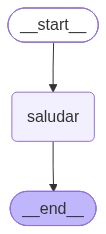

In [10]:
ver_grafo(app)

#### Ejercicio

- Agregar un nodo más al grafo, que se denominara "nuevo_saludo"

---
## Ejercicio 2 — Dos nodos unidos por una arista

### Concepto
Con dos nodos, el estado **viaja** de uno a otro: el segundo nodo lee lo que escribió el primero.

```
START ──▶ consultar ──▶ formatear ──▶ END
              │              │
       estado_pedido      mensaje        ← clave que agrega cada nodo
```

`consultar` busca el pedido en el diccionario; `formatear` arma el mensaje para el cliente.

### Ejecutar

In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict


# 1. Estado
class EstadoPedido(TypedDict) :
    numero : str
    estado_pedido : str
    mensaje : str

# 2. Nodos

def consultar(estado: EstadoPedido) -> dict :
    respuesta = PEDIDOS.get(estado['numero'], "No existe pedido")
    return {
            "estado_pedido" : respuesta
            }
    
def formatear(estado: EstadoPedido) -> dict :
    respuesta = f"Su pedido {estado['numero']} esta {estado['estado_pedido']}"
    return {
            "mensaje" : respuesta
            }

# 3. Grafo

grafo = StateGraph(EstadoPedido)

# Agregar nodos
grafo.add_node("consultar",consultar)
grafo.add_node("formatear",formatear)

# Agregar aristas
grafo.add_edge(START , "consultar")
grafo.add_edge("consultar" , "formatear")
grafo.add_edge("formatear", END)


app = grafo.compile()
res = app.invoke({"numero": "48213"})

print(res["mensaje"])


Su pedido 482133 esta No existe pedido
